# Toy problem to demonstrate theory of ACFs

Take a system with observable $u=\hat{\psi})_1$, our computed estimate for the first eigenfunction.

Suppose the underlying exact expression is
$$
C_u(\tau) = 0.7\,\text{e}^{-\tau/1440} + 0.1\,\text{e}^{-\tau/60} + 0.1\,\text{e}^{-\tau/26} + 0.1\,\text{e}^{-\tau/2}
$$
where the the $\tau_i$ are the true timescales corresponding to the true eigenfunctions. 

Now, we want to produce data...

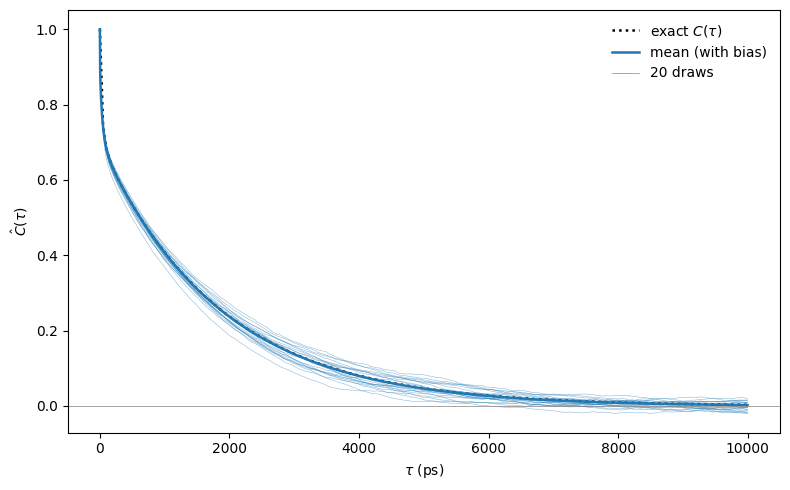

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from src.acf_toy import toy_model_acf, bartlett_acf_draws


def plot_acf_bartlett(taus, acf, acf_draws):
    draws, mean, stddev = acf_draws
    K = draws.shape[1]
    lags = np.arange(K) * 1.0  # frametime = 1

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(taus, acf.ct, "k:", lw=1.8, label="exact $C(\\tau)$")

    for d in draws:
        ax.plot(lags, d, color="tab:blue", lw=0.4, alpha=0.5)
    ax.plot(lags, mean, color="tab:blue", lw=1.8, label="mean (with bias)")
    ax.plot([], [], color="tab:blue", lw=0.4, label=f"{len(draws)} draws")

    ax.axhline(0, color="gray", lw=0.5)
    ax.set_xlabel(r"$\tau$ (ps)")
    ax.set_ylabel(r"$\hat C(\tau)$")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


taus = np.linspace(0, 10_000, 200)
acf = toy_model_acf(taus)
acf_draws = bartlett_acf_draws(
    acf.coeffs,
    acf.timescales,
    frametime=1,
    T=3_000_000,
    num_frames_acf=10_000,
    num_draws=20,
)
plot_acf_bartlett(taus, acf, acf_draws)